# K-Means Clustering - Performance Testing

This is another notebook to display the performance testing carried out on the K-Means program with different metrics on the spark-submit command to show interesting outcomes.

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

## Executor Scaling

In [24]:
executors = pd.read_excel("FYP_final_performance_tracker.xlsx", "KMeans - Executors")
executors[["num_executors", "total_cores", "runtime_seconds", "application_id"]]

,num_executors,total_cores,runtime_seconds,application_id
0,2,8,759.400,application_1774350804948_1016
1,4,16,644.356,application_1774350804948_1017
2,6,24,344.568,application_1774350804948_1019
3,8,32,310.096,application_1774350804948_1020
4,10,40,255.774,application_1774350804948_1021


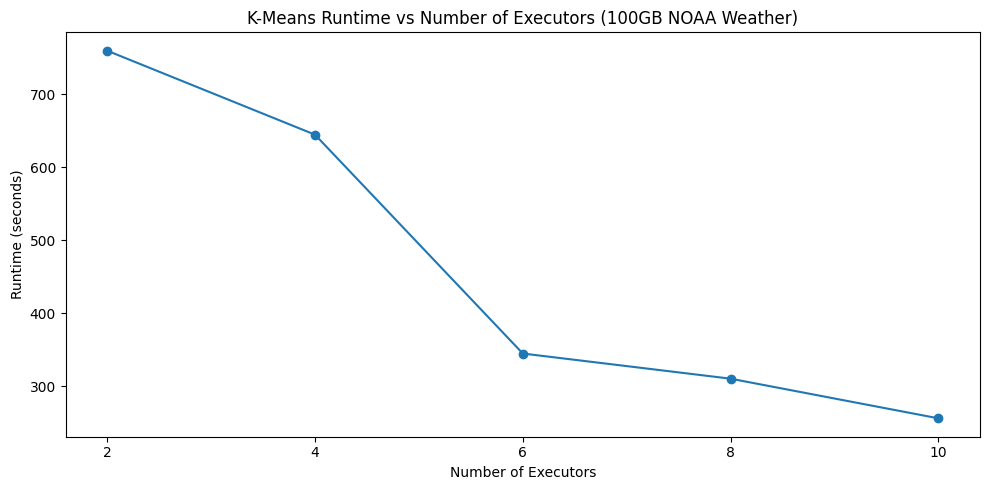

In [25]:
exec_clean = executors.copy()

exec_avg = exec_clean.groupby("num_executors").agg(
    runtime_mean=("runtime_seconds", "mean"),
    run_count=("runtime_seconds", "count")
).reset_index()

plt.figure(figsize=(10, 5))

plt.plot(exec_avg["num_executors"],
         exec_avg["runtime_mean"],
         marker="o")

plt.title("K-Means Runtime vs Number of Executors (100GB NOAA Weather)")
plt.xlabel("Number of Executors")
plt.ylabel("Runtime (seconds)")
plt.xticks(exec_avg["num_executors"])

plt.tight_layout()
plt.show()

## Break Down of Results - executors (runtime):

### Clear runtime improvement:
- Runtime drops as more executors are added to the job
- This stays consistent with the other workloads in the project

### Relative Speedup - Executors

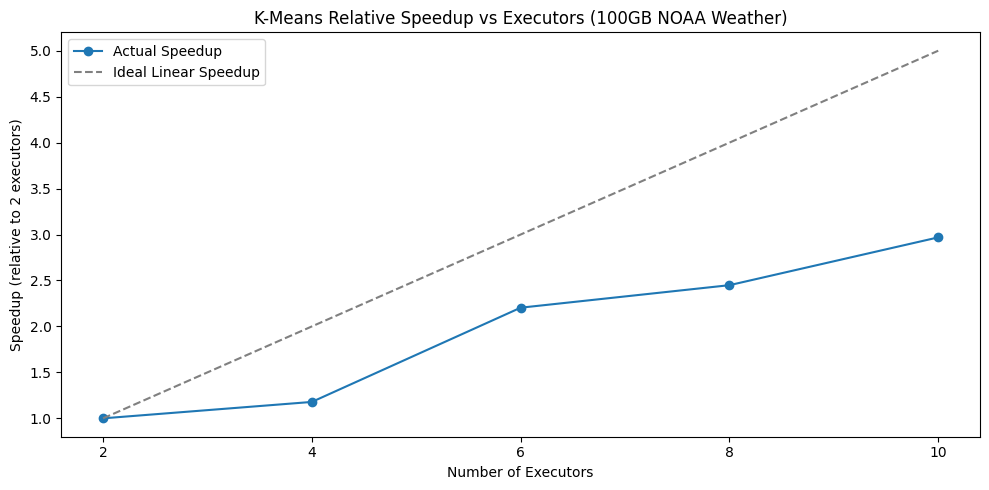

In [ ]:
baseline_runtime = exec_avg.iloc[0]["runtime_mean"] 

plt.figure(figsize=(10, 5))

speedup = baseline_runtime / exec_avg["runtime_mean"]
ideal = exec_avg["num_executors"] / exec_avg["num_executors"].iloc[0]

plt.plot(exec_avg["num_executors"], speedup, marker="o", label="Actual Speedup")
plt.plot(exec_avg["num_executors"], ideal, linestyle="--", color="gray", label="Ideal Linear Speedup")

plt.title("K-Means Relative Speedup vs Executors (100GB NOAA Weather)")
plt.xlabel("Number of Executors")
plt.ylabel("Speedup (relative to 2 executors)")
plt.xticks(exec_avg["num_executors"])
plt.legend()

plt.tight_layout()
plt.show()

## Break Down of Results - relative speedup:

### Speedup falls further below linear than stat analysis:
- The gap between actual and ideal speedup is larger for K-Means due to the iterative nature of the algorithm
- Each K-Means iteration requires a shuffle to reassign points to centroids, adding some overhead that limits the scaling

### Still worthwhile to scale:
- Despite falling short of the linear line, the improvement from 2 to 10 executors is still quite significant

## Partition Scaling

In [27]:
partitions = pd.read_excel("FYP_final_performance_tracker.xlsx", "KMeans - Partitions")
partitions[["shuffle_partitions", "runtime_seconds", "total_shuffle_read", "total_shuffle_write"]]

,shuffle_partitions,runtime_seconds,total_shuffle_read,total_shuffle_write
0,16,620.638,~1.0 GB,~1.0 GB
1,32,895.204,~1.1 GB,~1.1 GB
2,64,605.819,~1.1 GB,~1.1 GB
3,128,740.948,~1.2 GB,~1.2 GB
4,200,653.573,~1.3 GB,~1.3 GB
5,400,550.361,~1.4 GB,~1.4 GB
6,800,421.378,~1.6 GB,~1.6 GB
7,1200,677.628,~1.8 GB,~1.8 GB


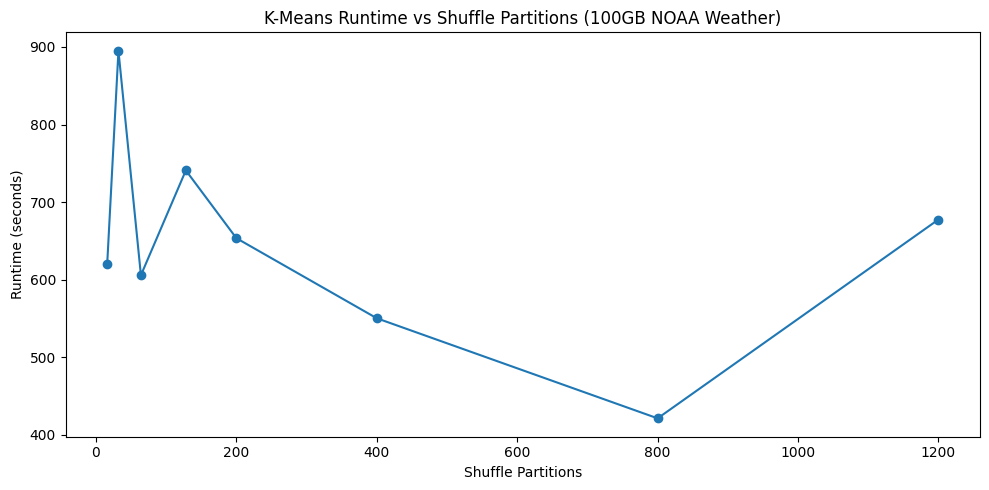

In [28]:
plt.figure(figsize=(10, 5))

plt.plot(partitions["shuffle_partitions"],
         partitions["runtime_seconds"],
         marker="o")

plt.title("K-Means Runtime vs Shuffle Partitions (100GB NOAA Weather)")
plt.xlabel("Shuffle Partitions")
plt.ylabel("Runtime (seconds)")

plt.tight_layout()
plt.show()

## Break Down of Results - partition: 

### Partition count has a more noticeable effect on K-Means:
- Unlike stat analysis where shuffle volume stayed constant at around 67MB, K-Means shuffle volume grows with partition count
- This is because the iterative reassignment step redistributes data across partitions each iteration

### Optimal range in partitions:
- The lowest runtimes appear in the 128-400 partition range
- Too few partitions does not utilise the available cores to its fullest potential
- Too many partitions increase shuffle overhead and task scheduling cost

## K-Means Shuffle Volume vs Partitions

Unlike StatAnalysis where shuffle volume was constant (~67MB), K-Means shuffle scales with partition count.

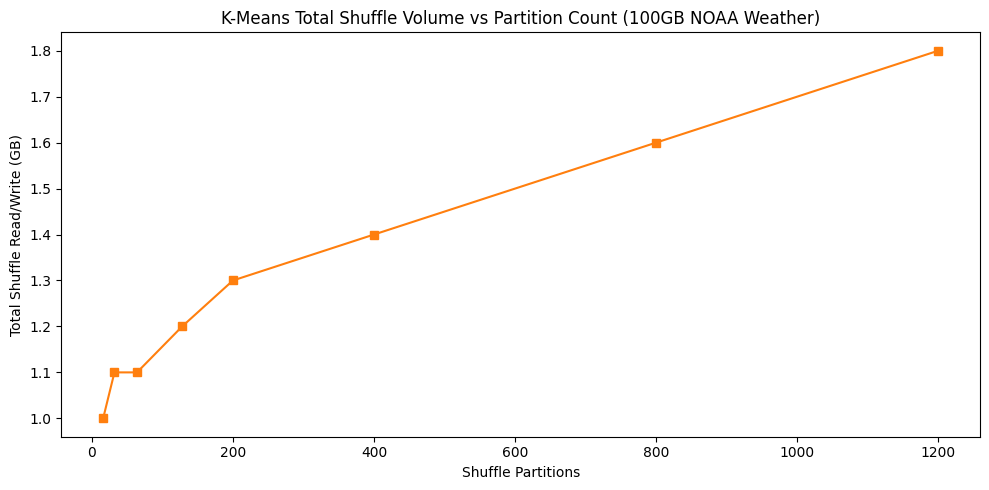

In [ ]:
# Extract numeric values from the approximate shuffle strings
shuffle_map = {16: 1.0, 32: 1.1, 64: 1.1, 128: 1.2, 200: 1.3, 400: 1.4, 800: 1.6, 1200: 1.8}
partitions["shuffle_gb"] = partitions["shuffle_partitions"].map(shuffle_map)

plt.figure(figsize=(10, 5))

plt.plot(partitions["shuffle_partitions"],
         partitions["shuffle_gb"],
         marker="s", color="tab:orange")

plt.title("K-Means Total Shuffle Volume vs Partition Count (100GB NOAA Weather)")
plt.xlabel("Shuffle Partitions")
plt.ylabel("Total Shuffle Read/Write (GB)")

plt.tight_layout()
plt.show()

## Break Down of Results - shuffle volume:

### Shuffle volume scales with partition count:
- This contrasts directly with stat analysis where shuffle stayed at 67MB regardless of partition count
- The K-Means algorithm requires data redistribution during each iteration, so more partitions means more shuffle traffic

### Implication for tuning:
- For K-Means workloads, partition count is a more sensitive tuning parameter than for simple aggregation workloads
- There is a trade-off between parallelism and shuffle overhead that needs to be balanced

## Executor scaling - Throughput

In [33]:
executors = pd.read_excel(
    "FYP_final_performance_tracker.xlsx",
    sheet_name="KMeans - Executors"
)

executors[["num_executors", "total_cores", "runtime_seconds", "throughput_mbps"]]

,num_executors,total_cores,runtime_seconds,throughput_mbps
0,2,8,759.400,137.72
1,4,16,644.356,162.31
2,6,24,344.568,303.53
3,8,32,310.096,337.27
4,10,40,255.774,408.91


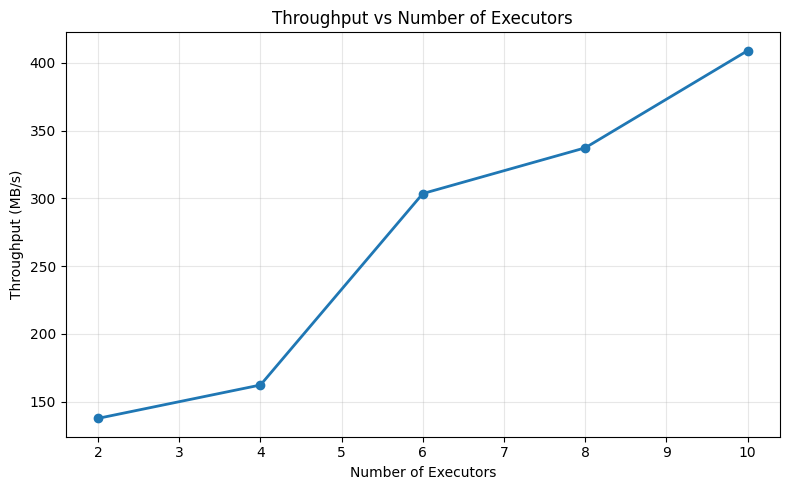

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(
    executors["num_executors"],
    executors["throughput_mbps"],
    marker="o",
    linestyle="-",
    linewidth=2
)

plt.xlabel("Number of Executors")
plt.ylabel("Throughput (MB/s)")
plt.title("Throughput vs Number of Executors")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Break Down of Results - throughput:

### Throughput increases with executors:
- Similar pattern to stat analysis, confirming that both workloads benefit from added parallelism